# Titanic Survival Prediction – Classification Project

**Goal:** predict whether a passenger survived the Titanic disaster (`Survived` = 1) or not (`Survived` = 0) using passenger details such as class, sex, age and fare.

**Dataset:** Kaggle Titanic `train.csv` (891 passengers, 12 columns).

**Models:** Logistic Regression and Random Forest Classifier.

## 1. Data Loading and Exploration

### 1.1 Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

sns.set_style("whitegrid")

### 1.2 Load the dataset

In [2]:
df = pd.read_csv("train.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### 1.3 Shape, data types and missing values

In [3]:
print("Shape:", df.shape)
print()
df.info()

Shape: (891, 12)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [4]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(1)
pd.DataFrame({"Missing": missing, "Percent (%)": missing_pct}).query("Missing > 0")

,Missing,Percent (%)
Age,177,19.9
Cabin,687,77.1
Embarked,2,0.2


- **Age** is missing for about 20% of passengers – we will fill it.
- **Cabin** is missing for about 77% – too much to fill reliably, so we will only keep whether a cabin was recorded.
- **Embarked** is missing for only 2 passengers.

### 1.4 Basic statistics

In [5]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [6]:
df.describe(include="object")

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,B96 B98,S
freq,1,577,7,4,644


In [7]:
df["Survived"].value_counts(normalize=True).round(3)

Survived
0    0.616
1    0.384
Name: proportion, dtype: float64

Only about **38%** of passengers survived, so the classes are somewhat imbalanced. This is why we look at precision, recall and F1, not just accuracy.

## 2. Data Visualisation

### 2.1 Univariate analysis
Looking at one variable at a time.

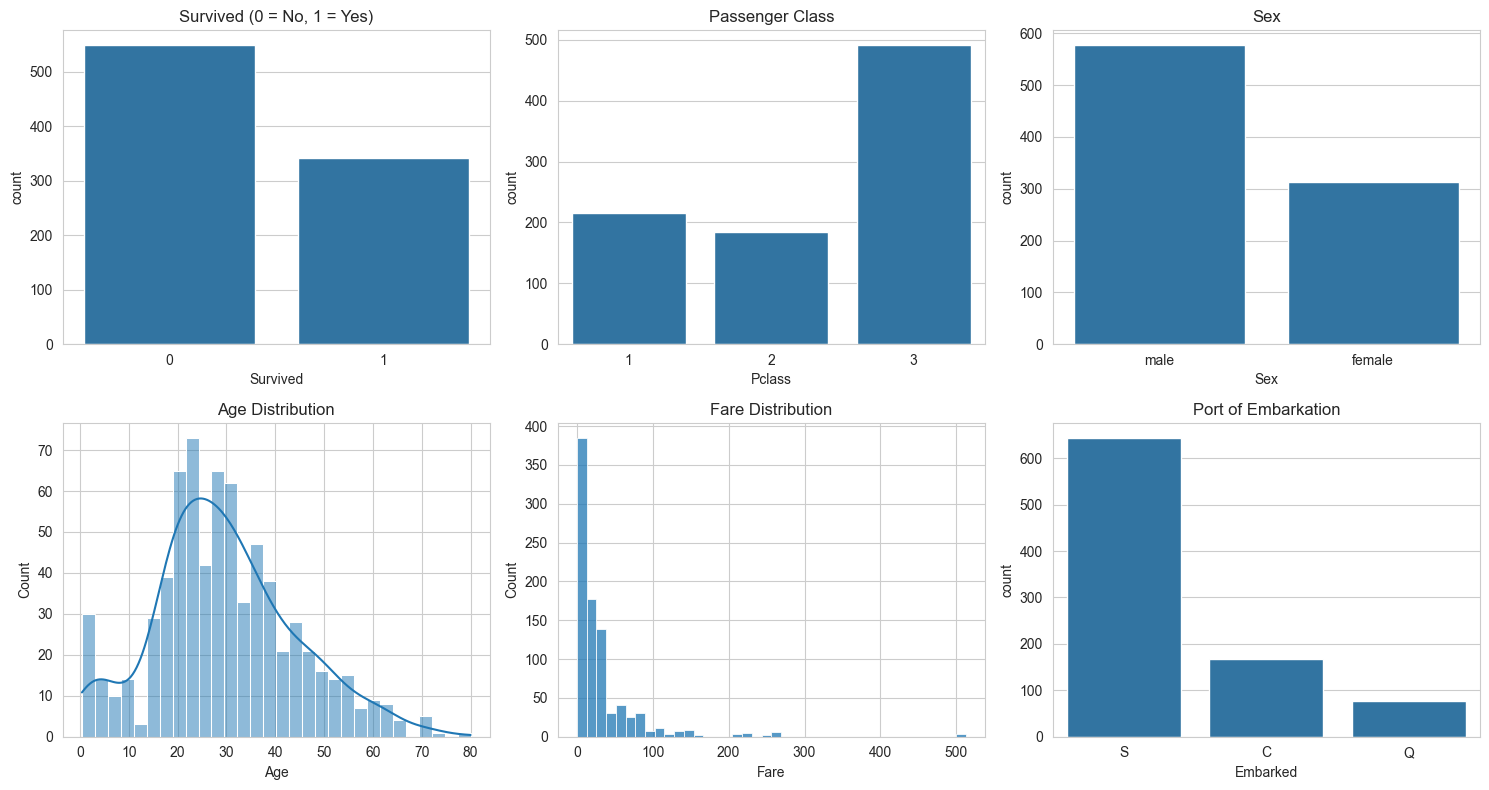

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

sns.countplot(x="Survived", data=df, ax=axes[0, 0])
axes[0, 0].set_title("Survived (0 = No, 1 = Yes)")

sns.countplot(x="Pclass", data=df, ax=axes[0, 1])
axes[0, 1].set_title("Passenger Class")

sns.countplot(x="Sex", data=df, ax=axes[0, 2])
axes[0, 2].set_title("Sex")

sns.histplot(df["Age"].dropna(), bins=30, kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Age Distribution")

sns.histplot(df["Fare"], bins=40, ax=axes[1, 1])
axes[1, 1].set_title("Fare Distribution")

sns.countplot(x="Embarked", data=df, ax=axes[1, 2])
axes[1, 2].set_title("Port of Embarkation")

plt.tight_layout()
plt.show()

**What this shows:**
- More passengers died than survived.
- Most passengers travelled in 3rd class, and there were almost twice as many males as females.
- Most passengers were aged 20–40.
- Fare is strongly right-skewed: most tickets were cheap, a few were very expensive.
- Most passengers boarded at Southampton (S).

### 2.2 Bivariate analysis
Looking at how each feature relates to survival.

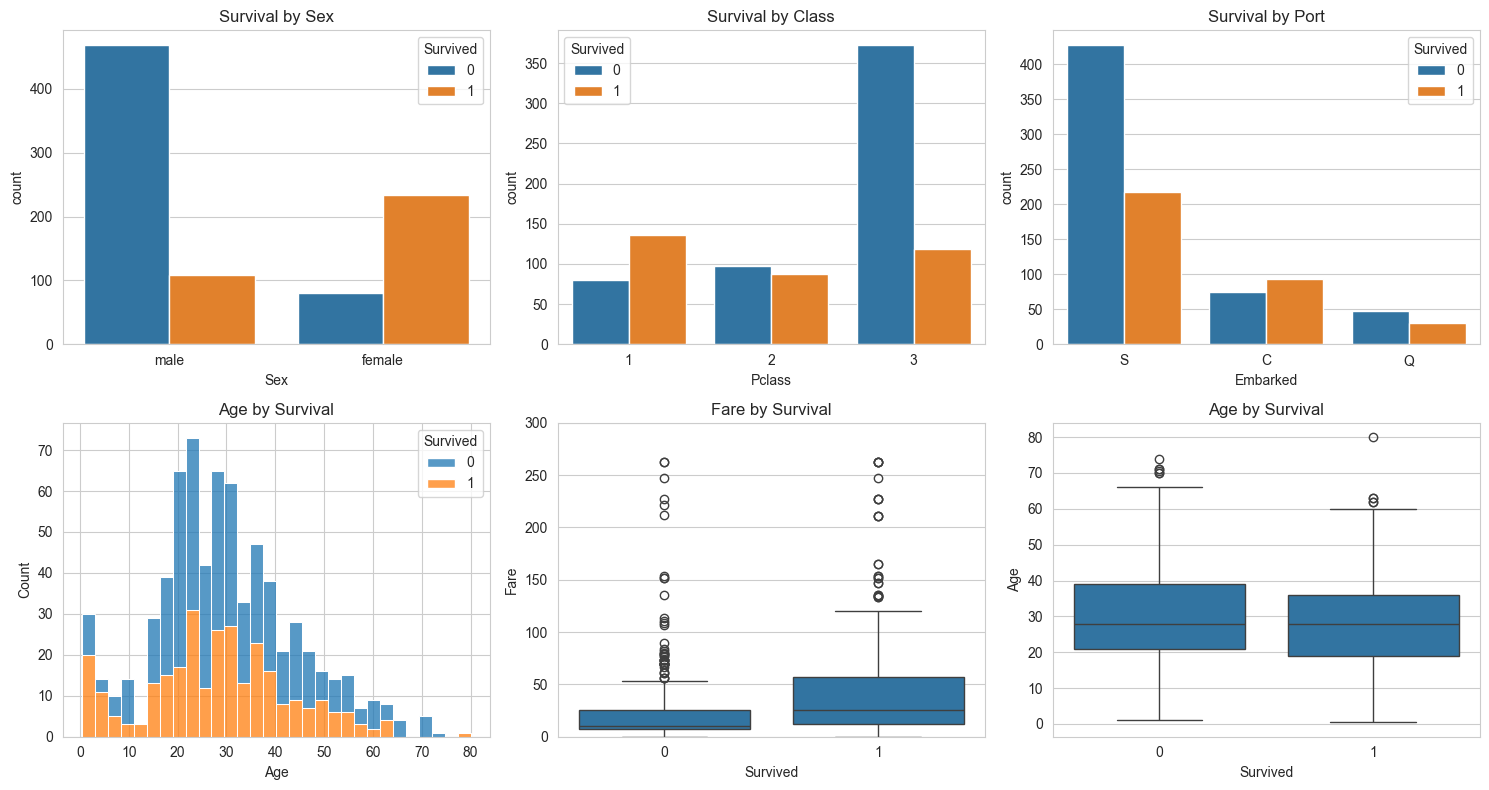

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

sns.countplot(x="Sex", hue="Survived", data=df, ax=axes[0, 0])
axes[0, 0].set_title("Survival by Sex")

sns.countplot(x="Pclass", hue="Survived", data=df, ax=axes[0, 1])
axes[0, 1].set_title("Survival by Class")

sns.countplot(x="Embarked", hue="Survived", data=df, ax=axes[0, 2])
axes[0, 2].set_title("Survival by Port")

sns.histplot(data=df, x="Age", hue="Survived", bins=30, multiple="stack", ax=axes[1, 0])
axes[1, 0].set_title("Age by Survival")

sns.boxplot(x="Survived", y="Fare", data=df, ax=axes[1, 1])
axes[1, 1].set_title("Fare by Survival")
axes[1, 1].set_ylim(0, 300)

sns.boxplot(x="Survived", y="Age", data=df, ax=axes[1, 2])
axes[1, 2].set_title("Age by Survival")

plt.tight_layout()
plt.show()

In [10]:
# Survival rate for key groups
print(df.groupby("Sex")["Survived"].mean().round(2), "\n")
print(df.groupby("Pclass")["Survived"].mean().round(2))

Sex
female    0.74
male      0.19
Name: Survived, dtype: float64 

Pclass
1    0.63
2    0.47
3    0.24
Name: Survived, dtype: float64


**What this shows:**
- **Sex** is the strongest signal: about 74% of women survived compared with about 19% of men.
- **Class** matters: 1st class passengers survived far more often (~63%) than 3rd class (~24%).
- Survivors generally paid **higher fares** (linked to class).
- Young children had a better chance of survival; age on its own is a weaker signal.

### 2.3 Multivariate analysis
Looking at several variables together.

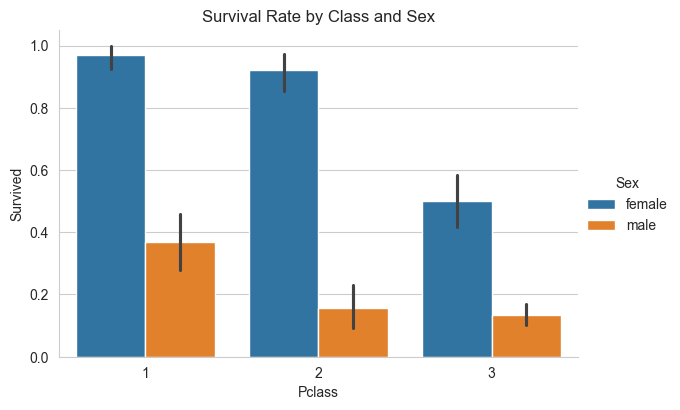

In [11]:
sns.catplot(x="Pclass", y="Survived", hue="Sex", data=df, kind="bar", height=4, aspect=1.5)
plt.title("Survival Rate by Class and Sex")
plt.show()

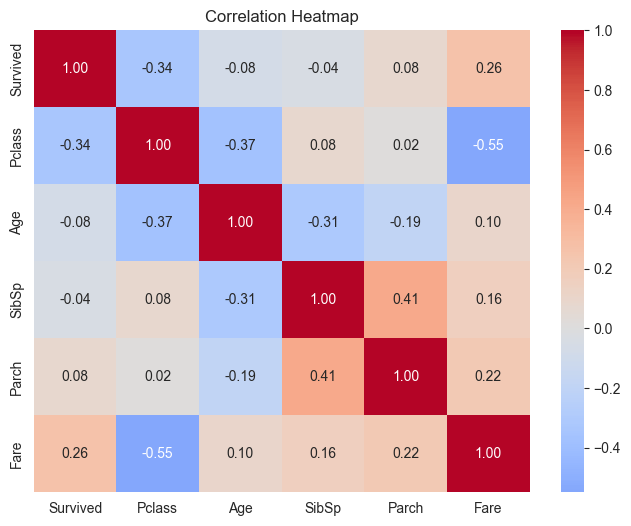

In [12]:
plt.figure(figsize=(8, 6))
numeric_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

**What this shows:**
- Women in 1st and 2nd class almost all survived, while men in 2nd and 3rd class rarely did – sex and class combine strongly.
- In the heatmap, `Survived` is negatively correlated with `Pclass` (higher class number → lower survival) and positively correlated with `Fare`.
- `Pclass` and `Fare` are strongly related to each other, and `SibSp` and `Parch` are related (both describe family on board).

## 3. Data Preprocessing and Feature Engineering

We work on a copy of the data so the original stays unchanged.

In [13]:
data = df.copy()

### 3.1 Create new features

- **Title** – extracted from the name (Mr, Mrs, Miss, Master, Rare). It captures sex, age group and social status.
- **FamilySize** – `SibSp + Parch + 1` (the passenger themself).
- **IsAlone** – 1 if the passenger travelled alone.
- **HasCabin** – 1 if a cabin number was recorded (often linked to wealthier passengers).

In [14]:
data["Title"] = data["Name"].str.extract(r",\s*([^\.]+)\.")[0]
data["Title"] = data["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
data["Title"] = data["Title"].where(data["Title"].isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")

data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
data["IsAlone"] = (data["FamilySize"] == 1).astype(int)
data["HasCabin"] = data["Cabin"].notnull().astype(int)

data["Title"].value_counts()

Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64

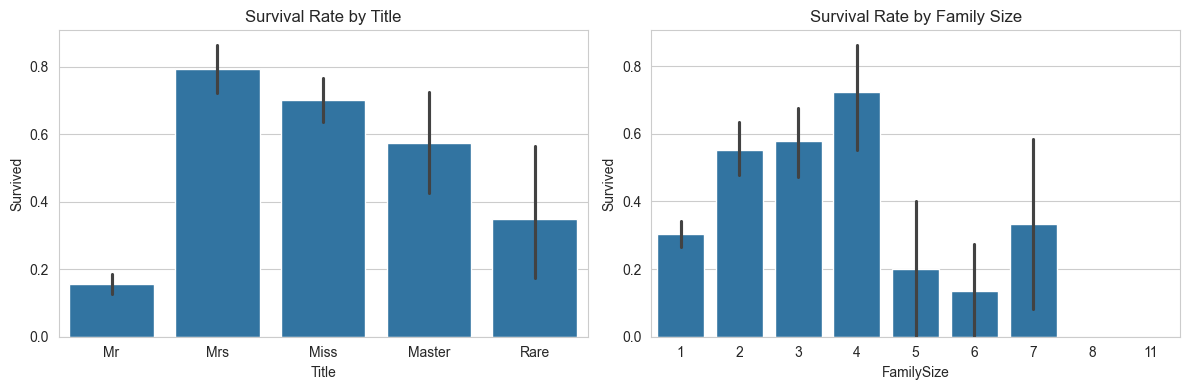

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x="Title", y="Survived", data=data, ax=axes[0])
axes[0].set_title("Survival Rate by Title")
sns.barplot(x="FamilySize", y="Survived", data=data, ax=axes[1])
axes[1].set_title("Survival Rate by Family Size")
plt.tight_layout()
plt.show()

Passengers with the titles Mrs, Miss and Master survived more often. Small families (2–4 people) had better survival than people travelling alone or in very large families.

### 3.2 Handle missing values

In [16]:
# Embarked: only 2 missing, so fill with the most common port
data["Embarked"] = data["Embarked"].fillna(data["Embarked"].mode()[0])

- **Cabin** is replaced by the `HasCabin` feature, so the original column will be dropped.
- **Age** will be filled with the median inside the pipeline (Section 4). Doing it there means the median is learned from the training data only, so no information from the test set leaks into training.

### 3.3 Remove unnecessary columns

`PassengerId` is just a row number, `Name` has been turned into `Title`, `Ticket` is a mostly unique code and `Cabin` has been replaced by `HasCabin`.

In [17]:
data = data.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])
data.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,FamilySize,IsAlone,HasCabin
0,0,3,male,22.0,1,0,7.2500,S,Mr,2,0,0
1,1,1,female,38.0,1,0,71.2833,C,Mrs,2,0,1
2,1,3,female,26.0,0,0,7.9250,S,Miss,1,1,0
3,1,1,female,35.0,1,0,53.1000,S,Mrs,2,0,1
4,0,3,male,35.0,0,0,8.0500,S,Mr,1,1,0


### 3.4 Convert categorical variables to numbers

In [18]:
# Sex has only two values, so a simple 0/1 mapping is enough
data["Sex"] = data["Sex"].map({"male": 0, "female": 1})
data.isnull().sum()

Survived        0
Pclass          0
Sex             0
Age           177
SibSp           0
Parch           0
Fare            0
Embarked        0
Title           0
FamilySize      0
IsAlone         0
HasCabin        0
dtype: int64

`Embarked` and `Title` have more than two categories with no natural order, so they will be **one-hot encoded** in the pipeline.

### 3.5 Scaling
Numerical features (`Age`, `Fare`, `FamilySize`, etc.) are on very different scales. Logistic Regression is sensitive to this, so we will apply **StandardScaler** in the pipeline. Random Forest does not need scaling, but using the same preprocessing for both models keeps the comparison fair.

## 4. Machine Learning Pipeline

### 4.1 Separate features (X) and target (y)

In [19]:
X = data.drop(columns="Survived")
y = data["Survived"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (891, 11)
y shape: (891,)


### 4.2 Train-test split
80% for training, 20% for testing. `stratify=y` keeps the same survival ratio in both sets.

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Training set:", X_train.shape)
print("Testing set: ", X_test.shape)

Training set: (712, 11)
Testing set:  (179, 11)


### 4.3 Preprocessing pipeline
- **Numerical features:** fill missing values with the median, then scale.
- **Categorical features:** one-hot encode.

In [21]:
numeric_features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "FamilySize", "IsAlone", "HasCabin"]
categorical_features = ["Embarked", "Title"]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

## 5. Model Training

Each model is placed in a pipeline with the same preprocessor, then trained on the same training split. These are the **baseline** models with default settings.

In [22]:
log_reg = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

rand_forest = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=42))
])

log_reg.fit(X_train, y_train)
rand_forest.fit(X_train, y_train)

print("Baseline Logistic Regression - test accuracy:", round(accuracy_score(y_test, log_reg.predict(X_test)), 4))
print("Baseline Random Forest       - test accuracy:", round(accuracy_score(y_test, rand_forest.predict(X_test)), 4))

Baseline Logistic Regression - test accuracy: 0.8324
Baseline Random Forest       - test accuracy: 0.7989


## 6. Hyperparameter Tuning

`GridSearchCV` tries every combination in a small grid and uses **5-fold cross-validation** on the training set to pick the best one. The test set is not used here.

- **Logistic Regression:** `C` controls regularisation strength (smaller = simpler model).
- **Random Forest:** number of trees, maximum tree depth and minimum samples per leaf.

In [23]:
lr_params = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__solver": ["lbfgs", "liblinear"]
}

lr_grid = GridSearchCV(log_reg, lr_params, cv=5, scoring="accuracy", n_jobs=-1)
lr_grid.fit(X_train, y_train)

print("Best parameters:", lr_grid.best_params_)
print("Best CV accuracy:", round(lr_grid.best_score_, 4))

Best parameters: {'model__C': 10, 'model__solver': 'lbfgs'}
Best CV accuracy: 0.8203


In [24]:
rf_params = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [4, 6, 8, None],
    "model__min_samples_leaf": [1, 2, 4]
}

rf_grid = GridSearchCV(rand_forest, rf_params, cv=5, scoring="accuracy", n_jobs=-1)
rf_grid.fit(X_train, y_train)

print("Best parameters:", rf_grid.best_params_)
print("Best CV accuracy:", round(rf_grid.best_score_, 4))

Best parameters: {'model__max_depth': 4, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}
Best CV accuracy: 0.8301


In [25]:
best_lr = lr_grid.best_estimator_
best_rf = rf_grid.best_estimator_

## 7. Model Evaluation

The tuned models are now tested on the unseen test set.

| Metric | Meaning |
|---|---|
| Accuracy | Share of all predictions that were correct |
| Precision | Of passengers predicted to survive, how many actually did |
| Recall | Of passengers who actually survived, how many the model found |
| F1-score | Balance between precision and recall |
| ROC-AUC | How well the model ranks survivors above non-survivors (0.5 = random, 1 = perfect) |

In [26]:
models = {"Logistic Regression": best_lr, "Random Forest": best_rf}
results = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }
    print(f"===== {name} =====")
    print(classification_report(y_test, y_pred, target_names=["Did not survive", "Survived"]))

===== Logistic Regression =====
                 precision    recall  f1-score   support

Did not survive       0.86      0.88      0.87       110
       Survived       0.80      0.77      0.79        69

       accuracy                           0.84       179
      macro avg       0.83      0.82      0.83       179
   weighted avg       0.84      0.84      0.84       179

===== Random Forest =====
                 precision    recall  f1-score   support

Did not survive       0.81      0.87      0.84       110
       Survived       0.77      0.67      0.71        69

       accuracy                           0.79       179
      macro avg       0.79      0.77      0.78       179
   weighted avg       0.79      0.79      0.79       179



### 7.1 Confusion matrices

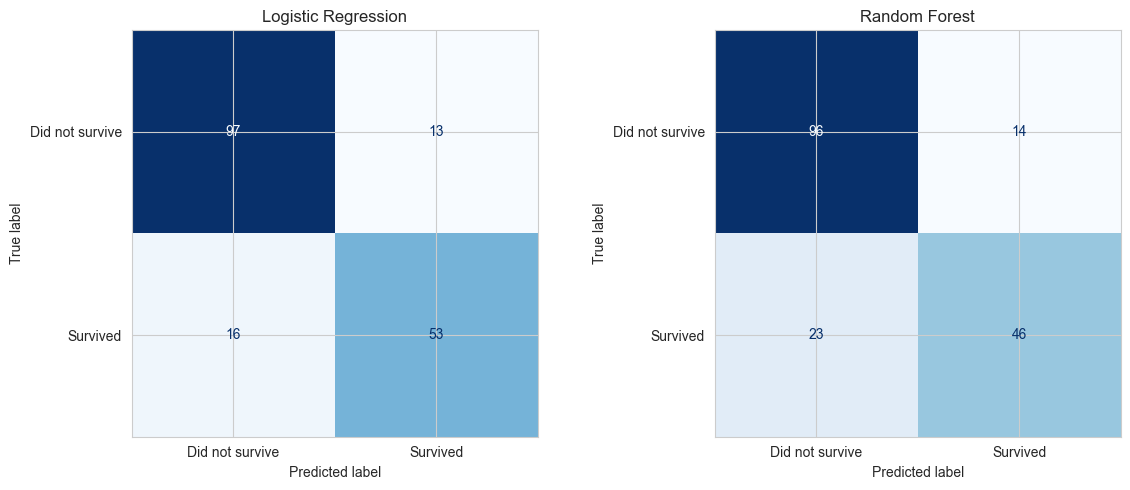

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=["Did not survive", "Survived"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

The diagonal shows correct predictions. Off-diagonal cells are mistakes: the top-right cell is passengers wrongly predicted to survive (false positives) and the bottom-left is survivors the model missed (false negatives).

### 7.2 ROC curves

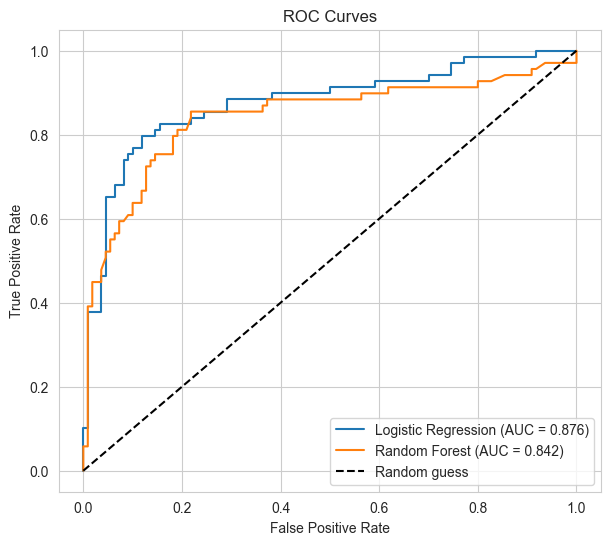

In [28]:
plt.figure(figsize=(7, 6))

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {results[name]['ROC-AUC']:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.show()

### 7.3 Explanation of results
- **Logistic Regression** reached about **84% accuracy**, an F1-score of **0.79** and a ROC-AUC of **0.88**. It found about 77% of the survivors (recall) and was right about 80% of the time when it predicted survival (precision).
- **Random Forest** reached about **79% accuracy**, an F1-score of **0.71** and a ROC-AUC of **0.84**. Its precision is similar, but its recall is lower (about 67%), so it missed more survivors.
- Both models are much better than guessing that nobody survived (about 62% accuracy), and both make more mistakes on survivors than on non-survivors because there are fewer survivors to learn from.

## 8. Model Comparison

### 8.1 Comparison table

In [29]:
comparison = pd.DataFrame(results).T.round(4)
comparison

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Logistic Regression,0.8380,0.8030,0.7681,0.7852,0.8759
Random Forest,0.7933,0.7667,0.6667,0.7132,0.8422


### 8.2 Accuracy and F1-score comparison

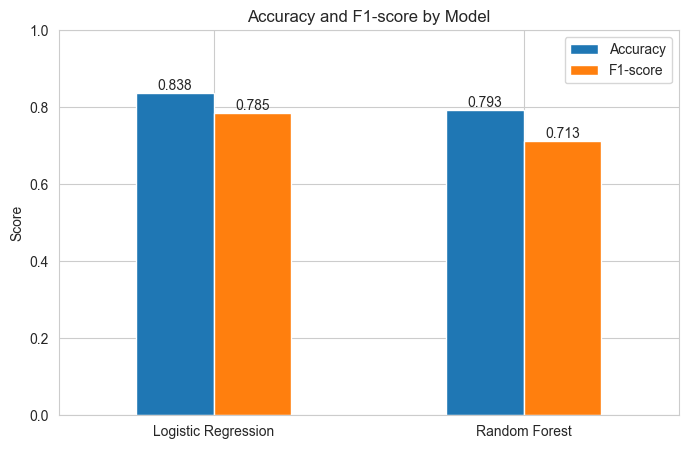

In [30]:
ax = comparison[["Accuracy", "F1-score"]].plot(kind="bar", figsize=(8, 5), rot=0)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Accuracy and F1-score by Model")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f")
plt.show()

### 8.3 Best model

In [31]:
best_model_name = comparison["F1-score"].idxmax()
print("Better-performing model (by F1-score):", best_model_name)
print()
print(comparison.loc[best_model_name])

Better-performing model (by F1-score): Logistic Regression

Accuracy     0.8380
Precision    0.8030
Recall       0.7681
F1-score     0.7852
ROC-AUC      0.8759
Name: Logistic Regression, dtype: float64


### 8.4 Feature importance (Random Forest)
This helps explain what the models relied on.

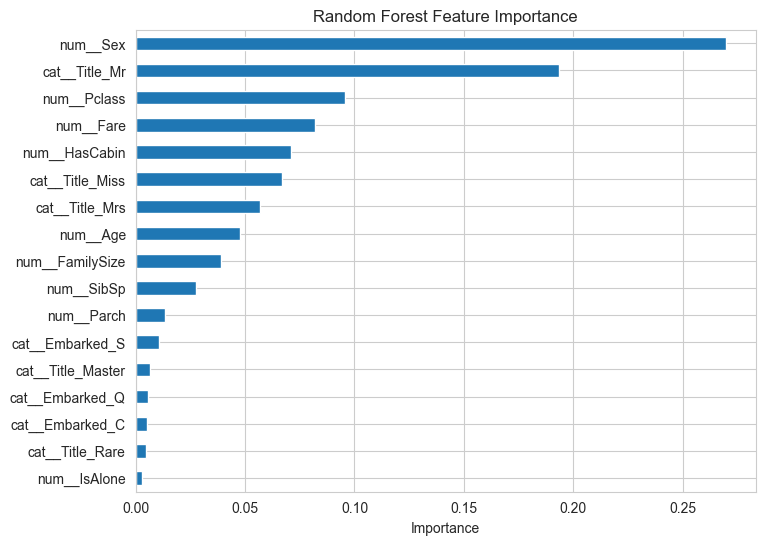

In [32]:
feature_names = best_rf.named_steps["preprocessor"].get_feature_names_out()
importances = pd.Series(best_rf.named_steps["model"].feature_importances_, index=feature_names)

importances.sort_values().plot(kind="barh", figsize=(8, 6))
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.show()

### 8.5 Why Logistic Regression performed better
**Logistic Regression is the better model here**, with higher scores on every metric on the test set.

- **The patterns are simple.** Survival depends mostly on a few strong features (sex, title, class and fare, as the feature importance chart shows), and each one pushes survival up or down in a fairly straight-line way. A linear model captures this well.
- **The dataset is small.** With only 712 training rows, a simpler model generalises more reliably. Random Forest is more flexible, so it is more likely to pick up noise even after tuning limited the tree depth to 4.
- **The good feature engineering helps the linear model.** Features like `Title`, `FamilySize` and `HasCabin` already express the useful patterns, so Random Forest's ability to find complex interactions adds little.

**Note:** in cross-validation, Random Forest scored slightly higher (0.830 vs 0.820), but the test set has only 179 passengers. A few predictions can change the result, so the two models are closer than the test scores suggest. Logistic Regression is still the better choice because it did better on unseen data and is simpler to interpret.

## 9. Conclusion

- **Exploration** showed that 38% of passengers survived and that **sex**, **passenger class** and **fare** were the strongest signs of survival: women and 1st class passengers were far more likely to survive.
- **Preprocessing** filled missing `Embarked` and `Age` values, dropped unhelpful columns, encoded categorical variables and scaled numerical features. New features (**Title**, **FamilySize**, **IsAlone**, **HasCabin**) added useful information.
- **A single pipeline** handled imputation, encoding and scaling, so both models were trained and tested the same way, without information leaking from the test set.
- **GridSearchCV** with 5-fold cross-validation tuned both models using small parameter grids.
- **Results:** the tuned **Logistic Regression** model performed best, with about **84% accuracy, 0.79 F1-score and 0.88 ROC-AUC**. Random Forest reached about 79% accuracy and a 0.71 F1-score.
- **Overall**, a simple, well-prepared linear model was enough to predict Titanic survival accurately. The main limitation is the small dataset; future work could try a larger test set or repeated cross-validation to get more stable comparisons.